# College to NBA: Rookie Projections

Population: NBA players who debuted from 2009-10 through 2025-26 after playing college basketball, with a final college season from 2009-10 on (when per-100 and advanced college stats begin) and at most one season between college and the NBA. The 2026 draft class is projected at the end.

| Feature family | Features |
|---|---|
| Draft slot | Overall pick (log scale; undrafted = 61), drafted flag |
| Recruiting rank | RSCI top-100 rank (unranked = 150) |
| Age, size | Age on June 25 after the final college season; height; weight |
| Position & conference | Listed college position; power-conference flag |
| Role & experience | Final-season games, minutes, starts; class; college seasons; career minutes |
| Box score & advanced | Final-season per-100 stats, shooting splits, usage, rate stats, OBPM / DBPM / BPM (schedule-adjusted), WS/40; career FT%, 3P% and BPM |

| Target | Definition |
|---|---|
| Rookie minutes per game | First NBA season |
| Rookie BPM | First NBA season, players with 500+ minutes |
| Minutes, first four seasons | Total regular-season minutes in seasons 1-4 (zero for seasons out of the league); debuts through 2022-23 |
| BPM, first four seasons | Minutes-weighted, players with 2,000+ minutes in seasons 1-4 |

Model: the average of shallow gradient boosted trees (pick constrained so a later pick never raises the projection) and a ridge regression. Every score and prediction below is out of sample: each draft class is predicted by a model trained on the other classes.

Sources: Basketball-Reference (player pages, advanced and per-game tables, 2026 draft), Sports-Reference college basketball.

In [1]:
import pandas as pd
import plotly.io as pio

from nba_analytics.players.rookies import (FEATURE_SETS, TARGETS, evaluate, family_importance,
                                           out_of_fold, project_draft_class, rookie_dataset)
from nba_analytics.players.rookies_plots import (plot_cv_scores, plot_draft_class,
                                                 plot_importance, plot_predicted_vs_actual)

# Interactive in JupyterLab / VS Code; static PNG fallback where Plotly can't run (e.g. GitHub)
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 0.7
pd.set_option("display.max_rows", 100)

df = rookie_dataset(2010, 2026)
nba = df[~df["draft_class"]]
FULL = FEATURE_SETS["All (adds draft slot, RSCI)"]

In [2]:
pd.DataFrame({
    "Players": [len(nba), int(df["draft_class"].sum())],
    "Drafted": [int(nba["drafted"].sum()), int(df.loc[df["draft_class"], "drafted"].sum())],
    "Draft classes": [f"{nba['entry_year'].min()}-{nba['entry_year'].max()}", "2026"],
}, index=["NBA players (training)", "2026 draft class"])

,Players,Drafted,Draft classes
NBA players (training),1152,725,2010-2025
2026 draft class,54,54,2026


## Model accuracy

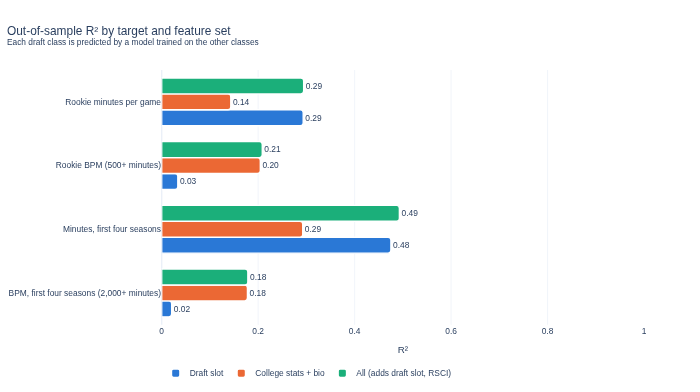

In [3]:
scores = evaluate(df)
plot_cv_scores(scores).show()

In [4]:
scores.pivot(index="target", columns="features", values=["r2", "mae"]).loc[
    list(TARGETS.values())].round(3)

r2  \
features                                 All (adds draft slot, RSCI)   
target                                                                 
Rookie minutes per game                                        0.294   
Rookie BPM (500+ minutes)                                      0.208   
Minutes, first four seasons                                    0.493   
BPM, first four seasons (2,000+ minutes)                       0.179   

                                                                         \
features                                 College stats + bio Draft slot   
target                                                                    
Rookie minutes per game                                0.143      0.293   
Rookie BPM (500+ minutes)                              0.204      0.033   
Minutes, first four seasons                            0.292      0.475   
BPM, first four seasons (2,000+ minutes)               0.178      0.021   

                                                                 mae  \
features                                 All (adds draft slot, RSCI)   
target                                                                 
Rookie minutes per game                                        5.723   
Rookie BPM (500+ minutes)                                      1.422   
Minutes, first four seasons                                 1588.439   
BPM, first four seasons (2,000+ minutes)                       1.307   

                                                                         
features                                 College stats + bio Draft slot  
target                                                                   
Rookie minutes per game                                6.401      5.668  
Rookie BPM (500+ minutes)                              1.429      1.604  
Minutes, first four seasons                         1900.498   1607.332  
BPM, first four seasons (2,000+ minutes)               1.311      1.442

## Feature family importance

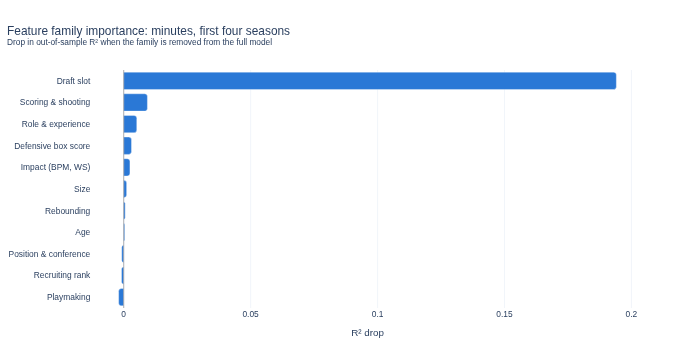

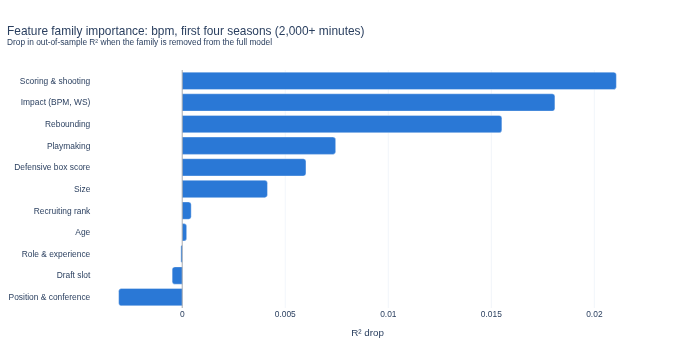

In [5]:
for target in ["mp_4yr", "bpm_4yr"]:
    plot_importance(family_importance(df, target), target).show()

## Predicted vs. actual

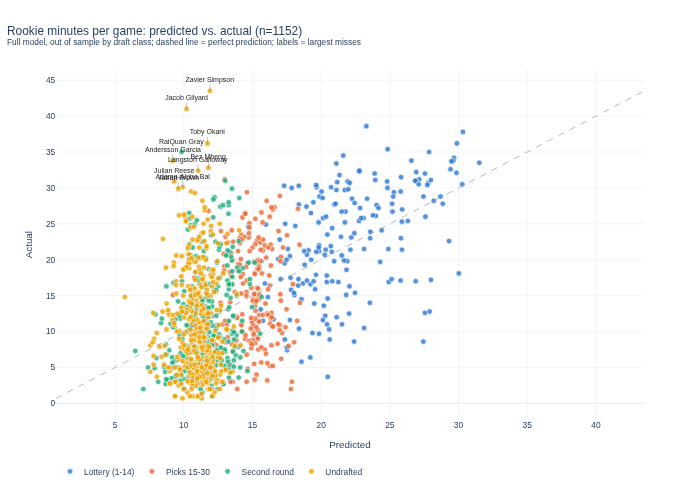

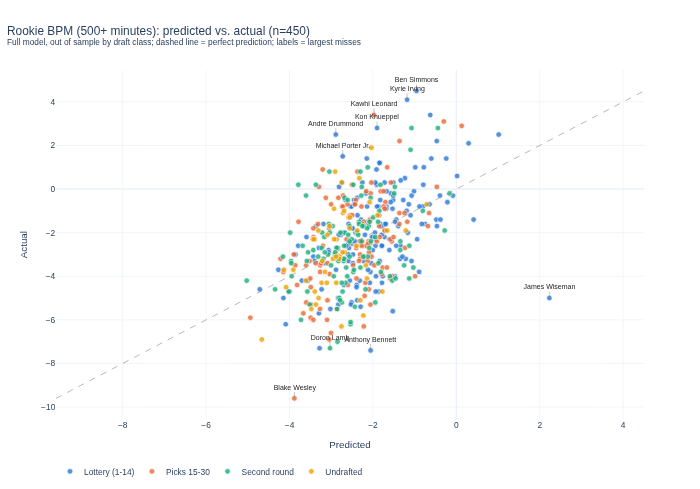

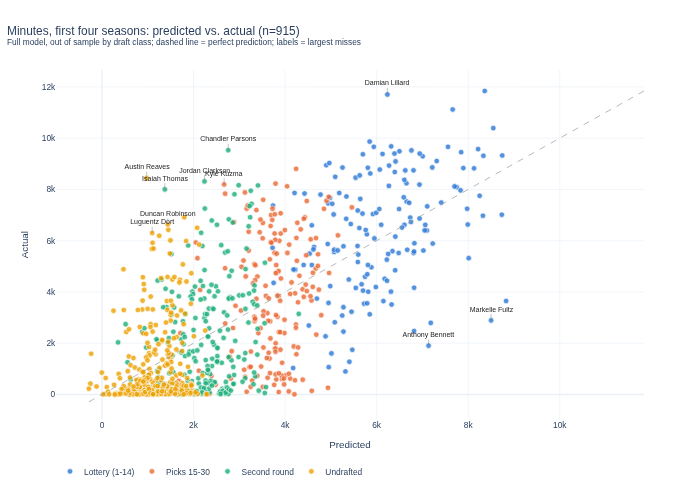

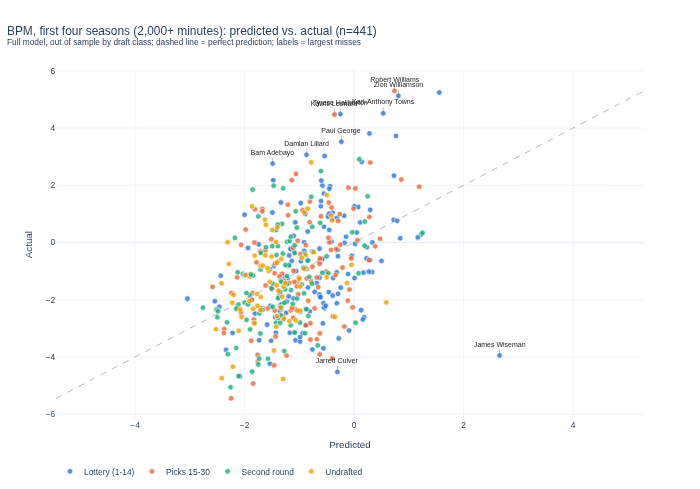

In [6]:
preds = {t: out_of_fold(df, t, FULL) for t in TARGETS}
for target in TARGETS:
    plot_predicted_vs_actual(df, preds[target], target).show()

## Biggest outperformers and underperformers: minutes, first four seasons

In [7]:
COLS = {"player": "Player", "school": "School", "entry_year": "Draft class",
        "draft_pick": "Pick", "age": "Age", "mp_4yr": "Actual", "pred": "Predicted",
        "resid": "Actual - predicted"}
miss = nba.loc[preds["mp_4yr"].index].assign(pred=preds["mp_4yr"])
miss["resid"] = miss["mp_4yr"] - miss["pred"]
miss = miss[list(COLS)].rename(columns=COLS).round(1)
miss.nlargest(15, "Actual - predicted")

,Player,School,Draft class,Pick,Age,Actual,Predicted,Actual - predicted
860,Austin Reaves,Oklahoma,2021,61.0,23.1,8440.0,976.6,7463.4
794,Chandler Parsons,Florida,2011,38.0,22.7,9531.0,2757.6,6773.4
1003,Isaiah Thomas,Washington,2011,60.0,22.4,8001.0,1373.1,6627.9
186,Jordan Clarkson,Missouri,2014,46.0,22.0,8313.0,2239.5,6073.5
581,Kyle Kuzma,Utah,2017,27.0,21.9,8195.0,2668.6,5526.4
612,Damian Lillard,Weber St.,2012,6.0,21.9,11705.0,6235.1,5469.9
261,Luguentz Dort,Arizona St.,2019,61.0,20.2,6300.0,1095.8,5204.2
884,Duncan Robinson,Michigan,2018,61.0,24.2,6632.0,1437.8,5194.2
690,Khris Middleton,Texas A&M,2012,39.0,20.9,8165.0,2986.1,5178.9
672,Jaden McDaniels,Washington,2020,28.0,19.7,7835.0,2690.1,5144.9


In [8]:
miss.nsmallest(15, "Actual - predicted")

,Player,School,Draft class,Pick,Age,Actual,Predicted,Actual - predicted
336,Markelle Fultz,Washington,2017,1.0,19.1,2891.0,8500.5,-5609.5
71,Anthony Bennett,UNLV,2013,1.0,20.3,1905.0,7134.8,-5229.8
1121,Zion Williamson,Duke,2019,1.0,19.0,3650.0,8828.4,-5178.4
3,Jordan Adams,UCLA,2014,22.0,20.0,263.0,4936.8,-4673.8
962,Zhaire Smith,Texas Tech,2018,16.0,19.1,143.0,4583.3,-4440.3
97,James Bouknight,UConn,2021,11.0,20.8,900.0,5318.8,-4418.8
1129,James Wiseman,Memphis,2020,2.0,19.2,2794.0,7182.3,-4388.3
221,Jarrett Culver,Texas Tech,2019,6.0,20.3,2480.0,6818.6,-4338.6
1092,Royce White,Iowa St.,2012,16.0,21.2,9.0,4203.8,-4194.8
234,Johnny Davis,Wisconsin,2022,10.0,20.3,1278.0,5404.9,-4126.9


## College stats vs. draft slot

Players the college-only model projected for far more four-season minutes than the draft-slot-only model, and the reverse. Both out of sample.

In [9]:
college = out_of_fold(df, "mp_4yr", FEATURE_SETS["College stats + bio"])
slot = out_of_fold(df, "mp_4yr", FEATURE_SETS["Draft slot"])
gap = nba.loc[college.index].assign(college_proj=college, slot_proj=slot,
                                    gap=college - slot)
GAP_COLS = {**{k: v for k, v in COLS.items() if k in ["player", "school", "entry_year",
                                                       "draft_pick", "mp_4yr"]},
            "college_proj": "College-only projection", "slot_proj": "Draft-slot projection",
            "gap": "College - slot"}
gap = gap[list(GAP_COLS)].rename(columns=GAP_COLS).round(0)
gap.nlargest(15, "College - slot")

,Player,School,Draft class,Pick,Actual,College-only projection,Draft-slot projection,College - slot
264,Devon Dotson,Kansas,2020,61.0,188.0,4841.0,1160.0,3682.0
822,Shamorie Ponds,St. John's (NY),2019,61.0,11.0,4589.0,1089.0,3500.0
618,Kenneth Lofton Jr.,Louisiana Tech,2022,61.0,375.0,4069.0,1097.0,2972.0
3,Jordan Adams,UCLA,2014,22.0,263.0,6618.0,3866.0,2752.0
761,Zach Norvell,Gonzaga,2019,61.0,41.0,3834.0,1089.0,2745.0
88,Bol Bol,Oregon,2019,44.0,1833.0,4891.0,2218.0,2673.0
806,Reggie Perry,Miss. St.,2020,57.0,398.0,4076.0,1412.0,2664.0
457,Markus Howard,Marquette,2020,61.0,381.0,3809.0,1160.0,2649.0
543,Mason Jones,Arkansas,2020,61.0,413.0,3737.0,1160.0,2578.0
168,Justin Champagnie,Pitt,2021,61.0,1890.0,3665.0,1108.0,2557.0


In [10]:
gap.nsmallest(15, "College - slot")

,Player,School,Draft class,Pick,Actual,College-only projection,Draft-slot projection,College - slot
1028,Evan Turner,Ohio St.,2010,2.0,8859.0,2934.0,7768.0,-4834.0
344,Darius Garland,Vanderbilt,2019,5.0,8491.0,1957.0,6748.0,-4790.0
71,Anthony Bennett,UNLV,2013,1.0,1905.0,3928.0,8604.0,-4677.0
526,Wesley Johnson,Syracuse,2010,4.0,6731.0,2586.0,7100.0,-4515.0
1033,Ekpe Udoh,Baylor,2010,6.0,4436.0,2176.0,6425.0,-4249.0
10,Cole Aldrich,Kansas,2010,11.0,1033.0,1292.0,5365.0,-4073.0
1117,Patrick Williams,Florida St.,2020,4.0,5902.0,3314.0,7194.0,-3880.0
274,Kris Dunn,Providence,2016,5.0,5516.0,2918.0,6765.0,-3848.0
600,Alex Len,Maryland,2013,5.0,5261.0,2998.0,6791.0,-3794.0
799,Adreian Payne,Michigan St.,2014,15.0,1403.0,984.0,4730.0,-3747.0


## 2026 draft class projections

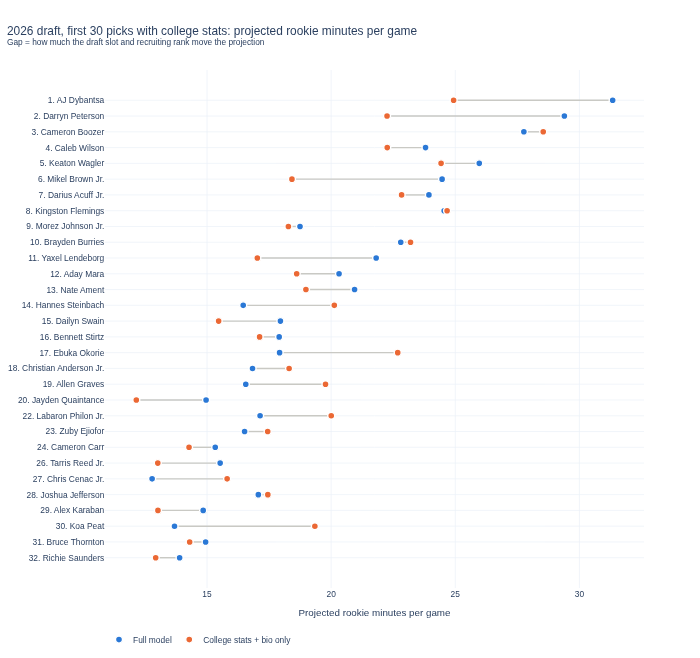

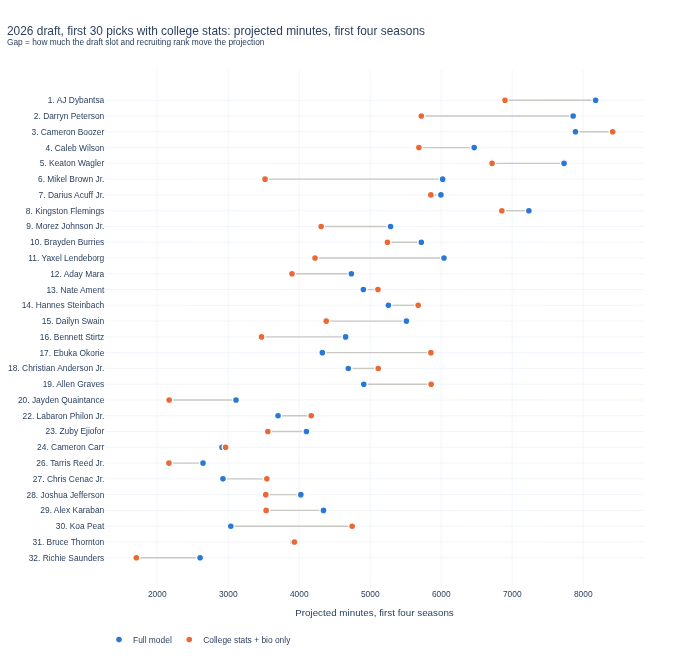

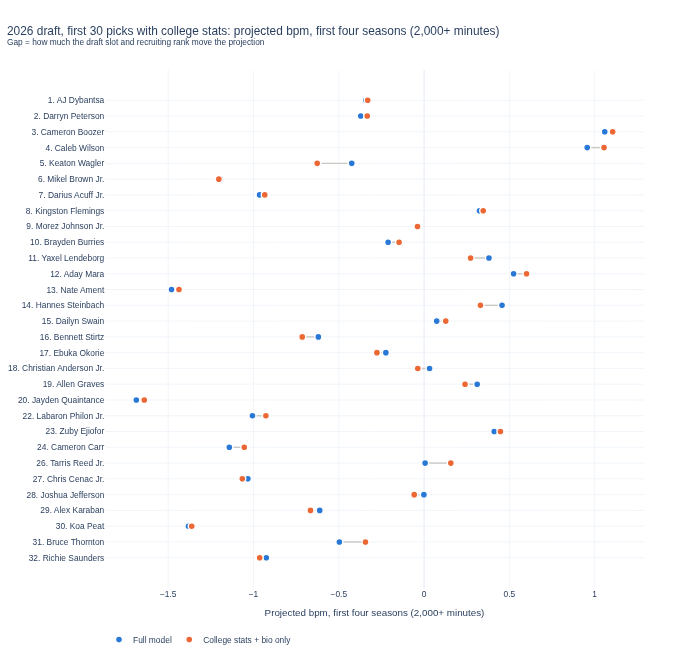

In [11]:
proj = project_draft_class(df)
for target in ["rookie_mpg", "mp_4yr", "bpm_4yr"]:
    plot_draft_class(proj, target).show()

In [12]:
PROJ_COLS = {"draft_pick": "Pick", "player": "Player", "school": "School", "age": "Age",
             "proj_rookie_mpg": "Rookie MPG", "proj_rookie_bpm": "Rookie BPM",
             "proj_mp_4yr": "Minutes, yrs 1-4", "proj_bpm_4yr": "BPM, yrs 1-4",
             "proj_mp_4yr_college": "Minutes, yrs 1-4 (college only)"}
proj[list(PROJ_COLS)].rename(columns=PROJ_COLS).round(1)

,Pick,Player,School,Age,Rookie MPG,Rookie BPM,"Minutes, yrs 1-4","BPM, yrs 1-4","Minutes, yrs 1-4 (college only)"
0,1.0,AJ Dybantsa,BYU,19.4,31.3,-1.4,8174.5,-0.3,6898.3
1,2.0,Darryn Peterson,Kansas,19.4,29.4,-1.4,7857.8,-0.4,5719.1
2,3.0,Cameron Boozer,Duke,18.9,27.8,-0.0,7890.5,1.1,8414.8
3,4.0,Caleb Wilson,UNC,19.9,23.8,0.1,6464.2,1.0,5685.5
4,5.0,Keaton Wagler,Illinois,19.4,26.0,-1.8,7730.0,-0.4,6716.4
5,6.0,Mikel Brown Jr.,Louisville,20.2,24.5,-3.1,6020.3,-1.2,3518.3
6,7.0,Darius Acuff Jr.,Arkansas,19.6,23.9,-2.6,5995.4,-1.0,5854.2
7,8.0,Kingston Flemings,Houston,19.5,24.6,-1.6,7234.4,0.3,6853.8
8,9.0,Morez Johnson Jr.,Michigan,20.4,18.7,-1.3,5286.6,-0.0,4308.6
9,10.0,Brayden Burries,Arizona,20.8,22.8,-1.6,5719.7,-0.2,5242.3
